In [52]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.lines import Line2D

from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import os
from sklearn.neighbors import KernelDensity
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [53]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [54]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [55]:
latitude = [30,60]


In [56]:
ifs_on = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_on_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['tp']

ifs_off = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_2.8km_off_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle_3_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['tp']
ifs_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/ifs_cycle_4_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['tp']
icon_cycle3 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle_3_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['pr']
icon_cycle4 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/icon_cycle_4_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['pr']
cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/cesm2_1850-2014_ens_30-60N_temporal_corr_nonbinary.nc')['PRECT']
imerg = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/mid_lat_correlation/imerg_cesm2_grid_30-60N_temporal_corr_nonbinary.nc')['precipitation']
#ifs_cycle4 = ifs_cycle4.isel(year=slice(0,30))
#ifs_cycle4 = ifs_cycle4.stack(sample=("year", "time"))
icon_cycle4 = icon_cycle4.isel(year=slice(0,5))
#icon_cycle4 = icon_cycle4.stack(sample=("year", "time"))



In [79]:
print(imerg)

<xarray.DataArray 'precipitation' (year: 11, lat: 32, lon: 288)> Size: 406kB
array([[[0.543927, 0.312016, ..., 0.142425, 0.213564],
        [0.397305, 0.404931, ..., 0.188717, 0.138491],
        ...,
        [     nan,      nan, ...,      nan,      nan],
        [     nan,      nan, ...,      nan,      nan]],

       [[0.224404, 0.172754, ..., 0.177817, 0.158367],
        [0.177418, 0.144814, ..., 0.383812, 0.265342],
        ...,
        [     nan,      nan, ...,      nan,      nan],
        [     nan,      nan, ...,      nan,      nan]],

       ...,

       [[0.054464, 0.03781 , ..., 0.567845, 0.478061],
        [0.611676, 0.011927, ..., 0.227394, 0.54616 ],
        ...,
        [     nan,      nan, ...,      nan,      nan],
        [     nan,      nan, ...,      nan,      nan]],

       [[     nan,      nan, ...,      nan,      nan],
        [     nan,      nan, ...,      nan,      nan],
        ...,
        [     nan,      nan, ...,      nan,      nan],
        [     nan,      nan

In [57]:

land_sea_cesm2 = xr.open_dataset('/home/jwille/xenon_data/NextGEMS/CESM2/precip/24H/mask.nc')['MASK']
land_sea_cesm2 = land_sea_cesm2[0,:,:]
indexer = ((land_sea_cesm2.lat>=latitude[0]) & (land_sea_cesm2.lat<=latitude[1]))
land_sea_cesm2 = land_sea_cesm2.where(indexer,drop=True)
land_sea_cesm2 = land_sea_cesm2.assign_coords(lat=cesm2.lat, lon=cesm2.lon)

cesm2_land = cesm2.where(land_sea_cesm2 > 0, np.nan)


In [58]:
ifs_on_land = ifs_on.stack(sample=("lat", "lon"))
ifs_off_land = ifs_off.stack(sample=("lat", "lon"))
ifs_cycle3_land = ifs_cycle3.stack(sample=("year", "lat", "lon"))
ifs_cycle4_land = ifs_cycle4.stack(sample=("year", "lat", "lon"))
icon_cycle3_land = icon_cycle3.stack(sample=("year", "lat", "lon"))
icon_cycle4_land = icon_cycle4.stack(sample=("year", "lat", "lon"))
imerg_land = imerg.stack(sample=("year", "lat", "lon"))
cesm2_land = cesm2_land.stack(sample=("member", "year", "lat", "lon"))

In [59]:
ifs_on_land = ifs_on_land.where(~ifs_on_land.isnull(), drop=True)
ifs_off_land = ifs_off_land.where(~ifs_off_land.isnull(), drop=True)
ifs_cycle3_land = ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)
ifs_cycle4_land = ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)
icon_cycle3_land = icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)
icon_cycle4_land = icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)
imerg_land = imerg_land.where(~imerg_land.isnull(), drop=True)
cesm2_land = cesm2_land.where(~cesm2_land.isnull(), drop=True)


In [60]:
# 1D cos(lat) for CESM2
lat_rad_cesm2 = np.deg2rad(cesm2.lat)
coslat_cesm2 = np.cos(lat_rad_cesm2)

w_lat_cesm2 = xr.DataArray(
    coslat_cesm2,
    dims=['lat'],
    coords={'lat': cesm2.lat}
)

# Broadcast to (lat, lon) on CESM2 land mask
w_cesm2_2d = w_lat_cesm2.broadcast_like(land_sea_cesm2)
w_cesm2_2d = w_cesm2_2d.where(land_sea_cesm2 > 0)


In [61]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_cesm2_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, cesm2.shape),
    dims=cesm2.dims,
    coords=cesm2.coords,
)
w_cesm2_land = w_cesm2_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_cesm2_land = w_cesm2_land.stack(sample=("member", "year", "lat", "lon"))

# Align mask with data
w_cesm2_land = w_cesm2_land.where(~cesm2_land.isnull(), drop=True)



In [62]:
print(w_cesm2_2d)

<xarray.DataArray 'lat' (lat: 32, lon: 288)> Size: 74kB
array([[0.86049074, 0.86049074, 0.86049074, ..., 0.86049074, 0.86049074,
        0.86049074],
       [0.85199496, 0.85199496, 0.85199496, ..., 0.85199496, 0.85199496,
        0.85199496],
       [0.84326868, 0.84326868, 0.84326868, ..., 0.84326868, 0.84326868,
        0.84326868],
       ...,
       [       nan,        nan,        nan, ..., 0.53053907,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]])
Coordinates:
  * lat      (lat) float64 256B 30.63 31.57 32.51 33.46 ... 57.96 58.9 59.84
  * lon      (lon) float64 2kB 0.0 1.25 2.5 3.75 5.0 ... 355.0 356.2 357.5 358.8
    time     object 8B 2017-01-01 00:00:00
Attributes:
    long_name:  latitude
    units:      degrees_north


In [63]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_on_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_on.shape),
    dims=ifs_on.dims,
    coords=ifs_on.coords,
)
w_ifs_on_land = w_ifs_on_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_on_land = w_ifs_on_land.stack(sample=("lat", "lon"))

# Align mask with data
w_ifs_on_land = w_ifs_on_land.where(~ifs_on_land.isnull(), drop=True)


In [64]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_off_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_off.shape),
    dims=ifs_off.dims,
    coords=ifs_off.coords,
)
w_ifs_off_land = w_ifs_off_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_off_land = w_ifs_off_land.stack(sample=("lat", "lon"))

# Align mask with data
w_ifs_off_land = w_ifs_off_land.where(~ifs_off_land.isnull(), drop=True)


In [65]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_cycle3_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_cycle3.shape),
    dims=ifs_cycle3.dims,
    coords=ifs_cycle3.coords,
)
w_ifs_cycle3_land = w_ifs_cycle3_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_cycle3_land = w_ifs_cycle3_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_cycle3_land = w_ifs_cycle3_land.where(~ifs_cycle3_land.isnull(), drop=True)


In [66]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_ifs_cycle4_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, ifs_cycle4.shape),
    dims=ifs_cycle4.dims,
    coords=ifs_cycle4.coords,
)
w_ifs_cycle4_land = w_ifs_cycle4_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_ifs_cycle4_land = w_ifs_cycle4_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_ifs_cycle4_land = w_ifs_cycle4_land.where(~ifs_cycle4_land.isnull(), drop=True)


In [67]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_icon_cycle3_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, icon_cycle3.shape),
    dims=icon_cycle3.dims,
    coords=icon_cycle3.coords,
)
w_icon_cycle3_land = w_icon_cycle3_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_icon_cycle3_land = w_icon_cycle3_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_icon_cycle3_land = w_icon_cycle3_land.where(~icon_cycle3_land.isnull(), drop=True)


In [68]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_icon_cycle4_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, icon_cycle4.shape),
    dims=icon_cycle4.dims,
    coords=icon_cycle4.coords,
)
w_icon_cycle4_land = w_icon_cycle4_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_icon_cycle4_land = w_icon_cycle4_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_icon_cycle4_land = w_icon_cycle4_land.where(~icon_cycle4_land.isnull(), drop=True)


In [69]:
# Broadcast to full CESM2(domain: member, year, lat, lon)
w_imerg_full = xr.DataArray(
    np.broadcast_to(w_cesm2_2d.values, imerg.shape),
    dims=imerg.dims,
    coords=imerg.coords,
)
w_imerg_land = w_imerg_full.where(land_sea_cesm2 > 0, np.nan)

# Stack identically to cesm2_land
w_imerg_land = w_imerg_land.stack(sample=("year", "lat", "lon"))

# Align mask with data
w_imerg_land = w_imerg_land.where(~imerg_land.isnull(), drop=True)


In [70]:
print(np.median(imerg_land))


0.18960981


In [71]:
print(np.median(cesm2_land))

0.23741839809771997


In [72]:
print(np.median(ifs_off_land))

0.2193035216567424


In [73]:
print(np.median(ifs_on_land))

0.2473688454832879


In [74]:
print(np.median(icon_cycle4_land))

0.20434967


In [75]:
print(np.median(icon_cycle3_land))

0.2509692


In [76]:
print(np.median(ifs_cycle3_land))

0.22946822549141604


In [77]:
print(np.median(ifs_cycle4_land))

0.23056410301540106


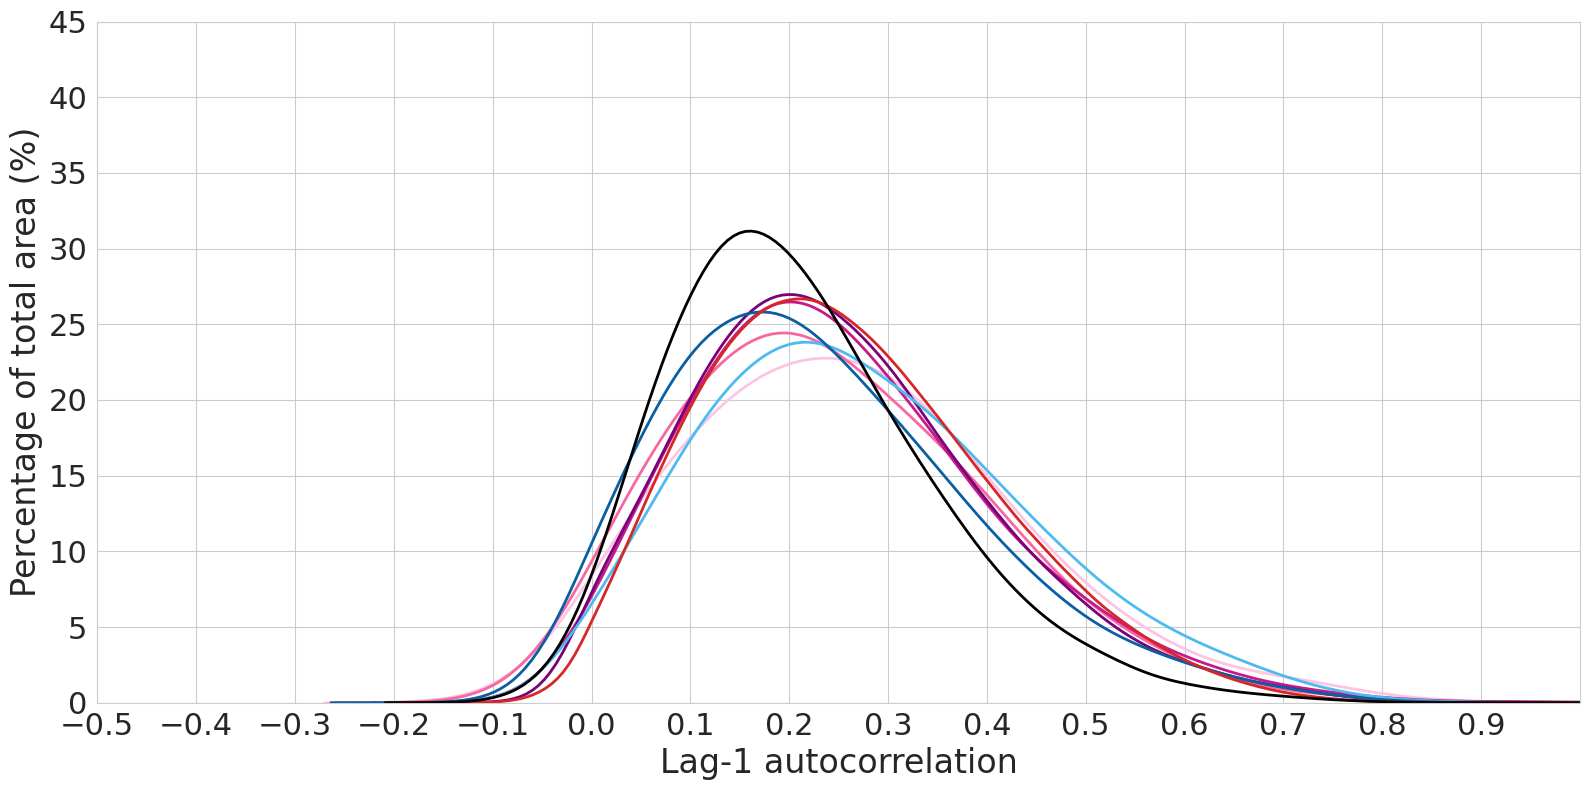

In [78]:
#with weights

# 1) Common x-range + bin width
xmin, xmax = -0.5, 1


bin_width  = 0.10


# For equal-area grids: weights = 1
def ones_like_da(da):
    return xr.ones_like(da)

datasets = [
    # IFS/ICON: equal-area → uniform weights
    (ifs_on_land,       w_ifs_on_land,       '#FCC5E4', 'IFS_2.8_deep_on'),
    (ifs_off_land,      w_ifs_off_land,      '#F768A1', 'IFS_2.8_deep_off'),
    (ifs_cycle3_land,   w_ifs_cycle3_land,   '#C51B8A', 'IFS_4.4-FESOM_5'),
    (ifs_cycle4_land,   w_ifs_cycle4_land,   '#7A0177', 'IFS_9-FESOM_5'),
    (icon_cycle3_land,  w_icon_cycle3_land,  '#4DBBEE', 'ICON_5'),
    (icon_cycle4_land,  w_icon_cycle4_land,  '#0A5FA3', 'ICON_9'),

    # CESM2 & IMERG: area weights from above
    (cesm2_land,        w_cesm2_land,                    '#D62728', 'CESM2'),
    (imerg_land,        w_imerg_land,                    '#000000',       'IMERG'),
]



plt.figure(figsize=(16, 8))
sns.set_style("whitegrid")
plt.rc('axes', titlesize=22)
plt.rc('axes', labelsize=18)

for data_da, wts_da, color, label in datasets:
    x = data_da.values.ravel()
    w = wts_da.values.ravel()

    sns.kdeplot(
        x=x,
        weights=w,
        bw_adjust=2.0,
        clip=(xmin, xmax),
        common_norm=False,
        fill=False,
        linewidth=2.0,
        color=color,
        label=label
    )

# 4) Rescale each line from density → percent per 0.5% bin
ax = plt.gca()
for line in ax.get_lines():
    x_vals, y_vals = line.get_data()
    y_scaled = y_vals * 100 * bin_width
    line.set_data(x_vals, y_scaled)

# 5) Labels, limits, legend
xl = 'Lag-1 autocorrelation'
ax.set_ylim(0, 45)
plt.xlabel(xl, fontsize=24)

plt.ylabel('Percentage of total area (%)', fontsize=24)


plt.xlim(xmin, xmax)
plt.tick_params(axis='both', which='major', labelsize=22)

xticks = np.arange(xmin, xmax, 0.1)
ax.set_xticks(xticks)

# build a list of Line2D handles matching your plotted lines
legend_handles = [
    Line2D([0], [0], color=color, linewidth=2.0)
    for *_, color, _ in datasets
]
# extract the labels out of your datasets tuple
legend_labels = [label for *_, _, label in datasets]

# then call legend with those handles
#plt.legend(
#    legend_handles,
#    legend_labels,
#    loc='upper right',
#    prop={'size': 22},
#    bbox_to_anchor=(1.0, 1.0),
#    handlelength=2.5  # longer lines in legend if you like
#)

plt.tight_layout()
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_temporal_corr_nonbinary_cesm2_grid_histo.pdf', format='pdf',bbox_inches='tight')

plt.show()